In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [ ]:
TRAIN_TSV = "../data/train.tsv"
DEV_TSV   = "../data/devel.tsv"
TEST_TSV  = "../data/test.tsv"

In [3]:
with open(TRAIN_TSV, "r", encoding="utf-8") as f:
    for i in range(10):
        print(f.readline())

Selegiline	B-Chemical

-	O

induced	O

postural	B-Disease

hypotension	I-Disease

in	O

Parkinson	B-Disease

'	I-Disease

s	I-Disease

disease	I-Disease



In [4]:
def load_iob_tsv(path):
    sentences = []
    tokens = []
    labels = []

    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.strip()

            # fin de phrase
            if line == "":
                if tokens:
                    sentences.append({
                        "tokens": tokens,
                        "labels": labels
                    })
                    tokens = []
                    labels = []
                continue

            parts = line.split()

            if len(parts) < 2:
                continue

            tokens.append(parts[0])
            labels.append(parts[-1])

    # dernier flush
    if tokens:
        sentences.append({
            "tokens": tokens,
            "labels": labels
        })

    return sentences

In [5]:
train_data = load_iob_tsv(TRAIN_TSV)

print("Nb sentences:", len(train_data))
print(train_data[0])

Nb sentences: 4560
{'tokens': ['Selegiline', '-', 'induced', 'postural', 'hypotension', 'in', 'Parkinson', "'", 's', 'disease', ':', 'a', 'longitudinal', 'study', 'on', 'the', 'effects', 'of', 'drug', 'withdrawal', '.'], 'labels': ['B-Chemical', 'O', 'O', 'B-Disease', 'I-Disease', 'O', 'B-Disease', 'I-Disease', 'I-Disease', 'I-Disease', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O']}


In [6]:
train_data = load_iob_tsv(TRAIN_TSV)
dev_data   = load_iob_tsv(DEV_TSV)
test_data  = load_iob_tsv(TEST_TSV)

In [7]:
print("Nb sentences:", len(train_data))
print(train_data[0])

Nb sentences: 4560
{'tokens': ['Selegiline', '-', 'induced', 'postural', 'hypotension', 'in', 'Parkinson', "'", 's', 'disease', ':', 'a', 'longitudinal', 'study', 'on', 'the', 'effects', 'of', 'drug', 'withdrawal', '.'], 'labels': ['B-Chemical', 'O', 'O', 'B-Disease', 'I-Disease', 'O', 'B-Disease', 'I-Disease', 'I-Disease', 'I-Disease', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O']}


In [8]:
print("Nb sentences:", len(dev_data))
print(dev_data[0])

Nb sentences: 4581
{'tokens': ['22', '-', 'oxacalcitriol', 'suppresses', 'secondary', 'hyperparathyroidism', 'without', 'inducing', 'low', 'bone', 'turnover', 'in', 'dogs', 'with', 'renal', 'failure', '.'], 'labels': ['B-Chemical', 'I-Chemical', 'I-Chemical', 'O', 'B-Disease', 'I-Disease', 'O', 'O', 'B-Disease', 'I-Disease', 'I-Disease', 'O', 'O', 'O', 'B-Disease', 'I-Disease', 'O']}


In [9]:
print("Nb sentences:", len(test_data))
print(test_data[0])

Nb sentences: 4797
{'tokens': ['Torsade', 'de', 'pointes', 'ventricular', 'tachycardia', 'during', 'low', 'dose', 'intermittent', 'dobutamine', 'treatment', 'in', 'a', 'patient', 'with', 'dilated', 'cardiomyopathy', 'and', 'congestive', 'heart', 'failure', '.'], 'labels': ['B-Disease', 'I-Disease', 'I-Disease', 'B-Disease', 'I-Disease', 'O', 'O', 'O', 'O', 'B-Chemical', 'O', 'O', 'O', 'O', 'O', 'B-Disease', 'I-Disease', 'O', 'B-Disease', 'I-Disease', 'I-Disease', 'O']}


In [10]:
import pandas as pd
def to_df(data):
    rows = []
    sent_id = 0

    for sent in data:
        for w, l in zip(sent["tokens"], sent["labels"]):
            rows.append([sent_id, w, l])
        sent_id += 1

    return pd.DataFrame(rows, columns=["sentence_id", "words", "labels"])

train_df = to_df(train_data)
dev_df   = to_df(dev_data)
test_df  = to_df(test_data)

In [11]:
train_df.head()

,sentence_id,words,labels
0,0,Selegiline,B-Chemical
1,0,-,O
2,0,induced,O
3,0,postural,B-Disease
4,0,hypotension,I-Disease


In [12]:
!pip install seqeval

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 584.3 kB/s eta 0:00:00 0:00:01
  Preparing metadata (setup.py) ... done
  Created wheel for seqeval: filename=seqeval-1.2.2-py3-none-any.whl size=16162 sha256=f5adb0a944e5fe0ef233eec4eb723a4a1b0158997f078f2899dd744bbabdc755
  Stored in directory: /root/.cache/pip/wheels/5f/b8/73/0b2c1a76b701a677653dd79ece07cfabd7457989dbfbdcd8d7
Successfully built seqeval


In [13]:
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForTokenClassification,
    get_linear_schedule_with_warmup,
)
from torch.optim import AdamW
from seqeval.metrics import f1_score as seq_f1, classification_report
from tqdm import tqdm

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Device: cuda


In [14]:
all_tags = set(tag for ex in train_data for tag in ex["labels"])

label_list = ["O"] + sorted(t for t in all_tags if t != "O")

label2id = {l:i for i,l in enumerate(label_list)}
id2label = {i:l for l,i in label2id.items()}

print("Labels:", label_list)

Labels: ['O', 'B-Chemical', 'B-Disease', 'I-Chemical', 'I-Disease']


In [15]:
from collections import Counter
import pandas as pd

def dataset_distribution(data, name="Dataset"):
    counter = Counter()

    for sent in data:
        counter.update(sent["labels"])

    df = pd.DataFrame(counter.items(), columns=["Label", "Count"])
    df = df.sort_values(by="Count", ascending=False)

    print(f"\n📊 {name} - Label Distribution")
    print(df.to_string(index=False))

    return df

In [16]:
train_stats = dataset_distribution(train_data, "TRAIN")
dev_stats   = dataset_distribution(dev_data, "DEV")
test_stats  = dataset_distribution(test_data, "TEST")


📊 TRAIN - Label Distribution
     Label  Count
         O 103967
B-Chemical   5203
 B-Disease   4182
 I-Disease   2918
I-Chemical   1900

📊 DEV - Label Distribution
     Label  Count
         O 103389
B-Chemical   5347
 B-Disease   4246
 I-Disease   2723
I-Chemical   1748

📊 TEST - Label Distribution
     Label  Count
         O 110576
B-Chemical   5385
 B-Disease   4424
 I-Disease   2737
I-Chemical   1628


In [17]:
import matplotlib.pyplot as plt
from collections import Counter

def plot_label_distribution(data, title):
    counter = Counter()

    for sent in data:
        counter.update(sent["labels"])

    labels = list(counter.keys())
    counts = list(counter.values())

    plt.figure(figsize=(10,5))
    plt.bar(labels, counts)

    plt.title(title)
    plt.xlabel("Labels")
    plt.ylabel("Nombre de tokens")
    plt.xticks(rotation=45)

    plt.show()

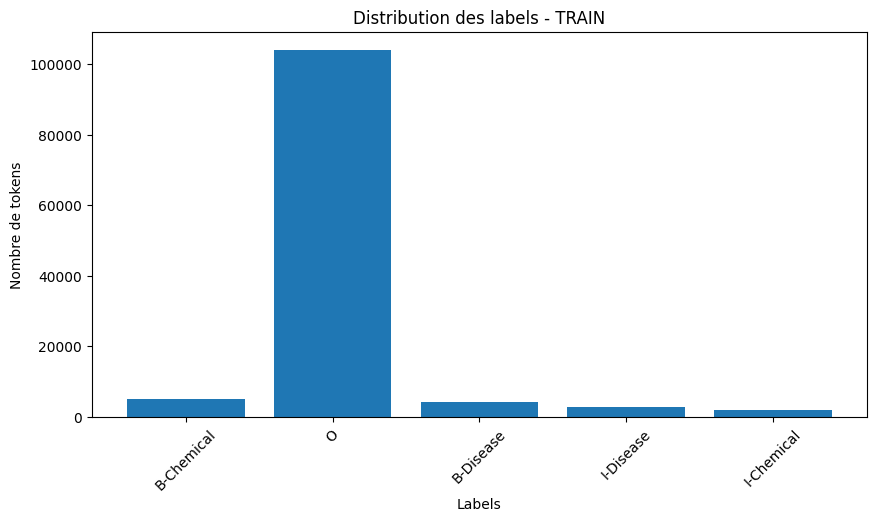

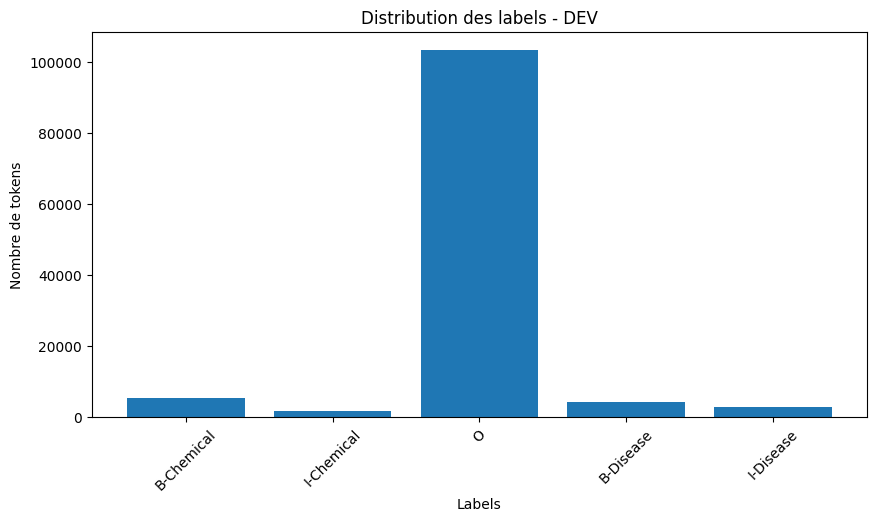

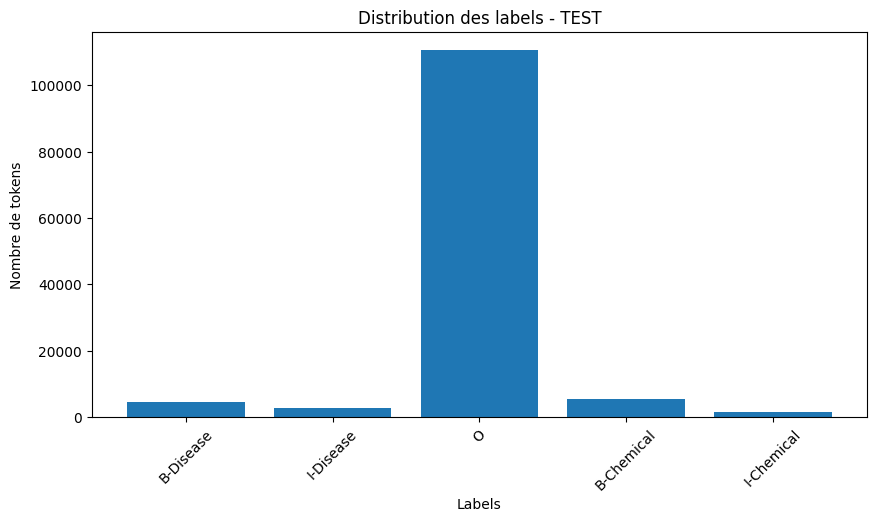

In [18]:
plot_label_distribution(train_data, "Distribution des labels - TRAIN")
plot_label_distribution(dev_data, "Distribution des labels - DEV")
plot_label_distribution(test_data, "Distribution des labels - TEST")

In [19]:
import torch
from transformers import AutoModelForTokenClassification, AutoTokenizer

MODEL_NAME = "emilyalsentzer/Bio_ClinicalBERT"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForTokenClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(label_list),
    id2label=id2label,
    label2id=label2id
).to(DEVICE)

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/436M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

BertForTokenClassification LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you

model.safetensors:   0%|          | 0.00/436M [00:00<?, ?B/s]

In [20]:
class NERDataset(torch.utils.data.Dataset):

    def __init__(self, data, tokenizer, label2id, max_len=128):
        self.data = data
        self.tokenizer = tokenizer
        self.label2id = label2id
        self.max_len = max_len

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):

        ex = self.data[idx]
        tokens = ex["tokens"]
        labels = ex["labels"]

        enc = self.tokenizer(
            tokens,
            is_split_into_words=True,
            truncation=True,
            padding="max_length",
            max_length=self.max_len,
            return_tensors="pt"
        )

        word_ids = enc.word_ids(batch_index=0)

        label_ids = []
        prev = None

        for w_id in word_ids:
            if w_id is None:
                label_ids.append(-100)
            elif w_id != prev:
                label_ids.append(self.label2id[labels[w_id]])
            else:
                label_ids.append(-100)
            prev = w_id

        enc = {k: v.squeeze(0) for k, v in enc.items()}
        enc["labels"] = torch.tensor(label_ids)

        return enc

In [21]:
from torch.utils.data import DataLoader

train_ds = NERDataset(train_data, tokenizer, label2id)
dev_ds   = NERDataset(dev_data, tokenizer, label2id)

train_loader = DataLoader(train_ds, batch_size=8, shuffle=True)
dev_loader   = DataLoader(dev_ds, batch_size=8)

In [22]:
loss_history = []
f1_history = []

In [23]:
from seqeval.metrics import f1_score

def evaluate(model, loader):

    model.eval()

    all_true = []
    all_pred = []

    with torch.no_grad():
        for batch in loader:

            labels = batch["labels"].cpu().numpy()
            batch = {k: v.to(DEVICE) for k, v in batch.items()}

            outputs = model(**batch)
            preds = outputs.logits.argmax(-1).cpu().numpy()

            for t_seq, p_seq in zip(labels, preds):

                true_seq, pred_seq = [], []

                for t, p in zip(t_seq, p_seq):

                    if t == -100:
                        continue

                    true_seq.append(id2label[int(t)])
                    pred_seq.append(id2label[int(p)])

                if len(true_seq) > 0:
                    all_true.append(true_seq)
                    all_pred.append(pred_seq)

    return all_true, all_pred

In [24]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from seqeval.metrics import f1_score
from torch.optim import AdamW
from tqdm import tqdm

optimizer = AdamW(model.parameters(), lr=2e-5)

loss_history = []
f1_history = []

for epoch in range(10):

    model.train()
    total_loss = 0

    loop = tqdm(train_loader, desc=f"Epoch {epoch+1}")

    for batch in loop:

        batch = {k: v.to(DEVICE) for k, v in batch.items()}

        optimizer.zero_grad()

        outputs = model(**batch)
        loss = outputs.loss

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        loop.set_postfix(loss=loss.item())

    # 📉 Loss
    avg_loss = total_loss / len(train_loader)
    loss_history.append(avg_loss)

    # 📊 Evaluation
    true, pred = evaluate(model, dev_loader)
    f1 = f1_score(true, pred)
    f1_history.append(f1)

    print(f"\nEpoch {epoch+1} - Loss: {avg_loss:.4f} | F1: {f1:.4f}")

Epoch 1: 100%|██████████| 570/570 [01:54<00:00,  4.97it/s, loss=0.0284]



Epoch 1 - Loss: 0.1596 | F1: 0.8586


Epoch 2: 100%|██████████| 570/570 [01:56<00:00,  4.90it/s, loss=0.0159] 



Epoch 2 - Loss: 0.0462 | F1: 0.8691


Epoch 3: 100%|██████████| 570/570 [01:56<00:00,  4.88it/s, loss=0.0182]  



Epoch 3 - Loss: 0.0227 | F1: 0.8746


... (10 outputs left out)

Epoch 9: 100%|██████████| 570/570 [01:56<00:00,  4.89it/s, loss=0.000181]



Epoch 9 - Loss: 0.0034 | F1: 0.8817


Epoch 10: 100%|██████████| 570/570 [01:56<00:00,  4.90it/s, loss=0.00459] 



Epoch 10 - Loss: 0.0042 | F1: 0.8793


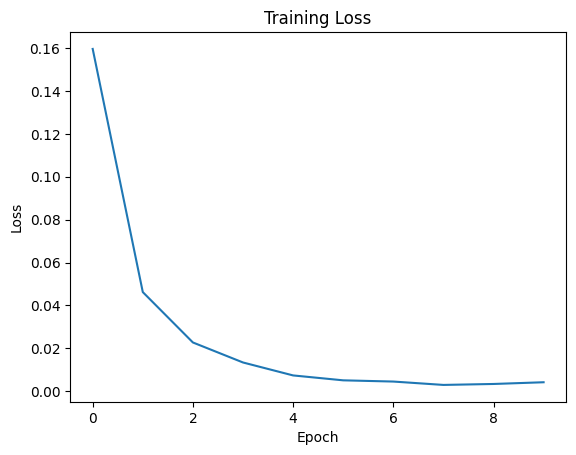

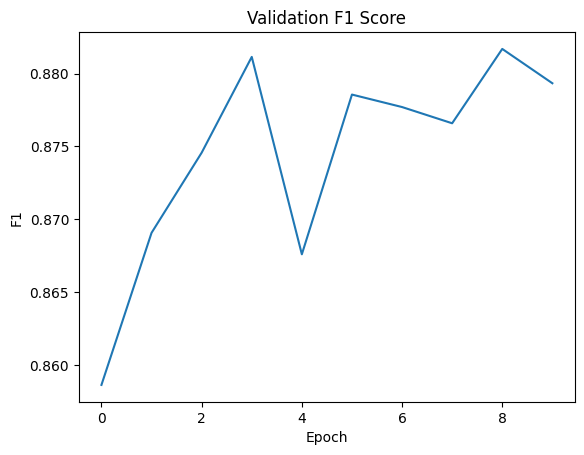

In [25]:
plt.figure()
plt.plot(loss_history)
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

plt.figure()
plt.plot(f1_history)
plt.title("Validation F1 Score")
plt.xlabel("Epoch")
plt.ylabel("F1")
plt.show()

In [26]:
def final_evaluation(model, loader):

    model.eval()

    all_true = []
    all_pred = []

    with torch.no_grad():
        for batch in loader:

            labels = batch["labels"].cpu().numpy()
            batch = {k: v.to(DEVICE) for k, v in batch.items()}

            outputs = model(**batch)
            preds = outputs.logits.argmax(-1).cpu().numpy()

            for t_seq, p_seq in zip(labels, preds):

                for t, p in zip(t_seq, p_seq):

                    if t == -100:
                        continue

                    all_true.append(id2label[int(t)])
                    all_pred.append(id2label[int(p)])

    # 📊 Classification report
    print(classification_report(all_true, all_pred, digits=4))

    # 📉 Confusion matrix
    labels = list(label2id.keys())

    cm = confusion_matrix(all_true, all_pred, labels=labels)

    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt="d",
                cmap="Blues",
                xticklabels=labels,
                yticklabels=labels)

    plt.title("Confusion Matrix - ClinicalBERT")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

    return all_true, all_pred

              precision    recall  f1-score   support

  B-Chemical     0.9543    0.9235    0.9386      5331
   B-Disease     0.8481    0.8663    0.8571      4240
  I-Chemical     0.9032    0.8080    0.8530      1698
   I-Disease     0.7801    0.7910    0.7855      2722
           O     0.9860    0.9881    0.9871    102803

    accuracy                         0.9735    116794
   macro avg     0.8943    0.8754    0.8842    116794
weighted avg     0.9735    0.9735    0.9735    116794



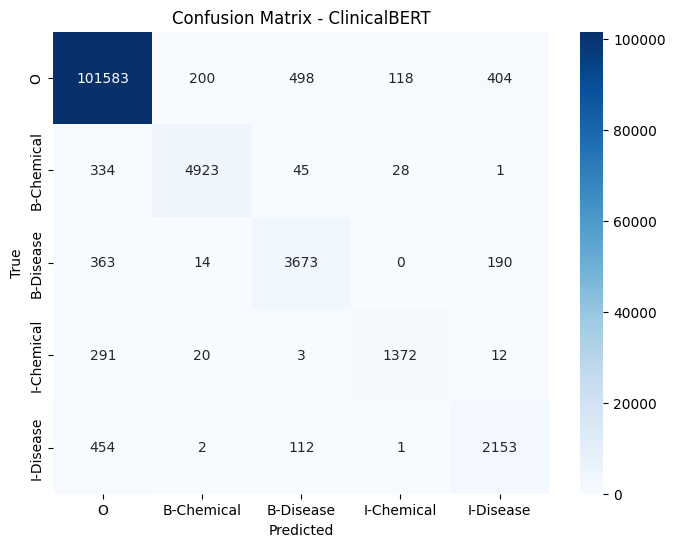

(['B-Chemical',
  'I-Chemical',
  'I-Chemical',
  'O',
  'B-Disease',
  'I-Disease',
  'O',
  'O',
  'B-Disease',
  'I-Disease',
  'I-Disease',
  'O',
  'O',
  'O',
  'B-Disease',
  'I-Disease',
  'O',
  'O',
  'O',
  'B-Chemical',
  'O',
  'O',
  'O',
  'O',
  'O',
  'O',
  'O',
  'O',
  'O',
  'O',
  'O',
  'O',
  'O',
  'B-Disease',
  'I-Disease',
  'O',
  'O',
  'O',
  'O',
  'O',
  'O',
  'B-Disease',
  'O',
  'O',
  'O',
  'O',
  'B-Disease',
  'I-Disease',
  'I-Disease',
  'I-Disease',
  'O',
  'O',
  'O',
  'O',
  'O',
  'B-Disease',
  'I-Disease',
  'I-Disease',
  'O',
  'O',
  'O',
  'B-Chemical',
  'I-Chemical',
  'O',
  'O',
  'B-Chemical',
  'I-Chemical',
  'I-Chemical',
  'O',
  'B-Chemical',
  'O',
  'O',
  'O',
  'O',
  'O',
  'O',
  'O',
  'O',
  'O',
  'O',
  'O',
  'O',
  'O',
  'O',
  'O',
  'O',
  'O',
  'O',
  'O',
  'B-Chemical',
  'O',
  'O',
  'O',
  'O',
  'O',
  'O',
  'O',
  'O',
  'O',
  'O',
  'O',
  'O',
  'B-Disease',
  'I-Disease',
  'I-Disease',
  'O',

In [27]:
final_evaluation(model, dev_loader)

In [29]:
import os

save_dir = "clinicalbert_saved_model"
os.makedirs(save_dir, exist_ok=True)

In [30]:
# modèle PyTorch
model.save_pretrained(save_dir)

# tokenizer
tokenizer.save_pretrained(save_dir)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('clinicalbert_saved_model/tokenizer_config.json',
 'clinicalbert_saved_model/tokenizer.json')

In [31]:
import json

with open(os.path.join(save_dir, "label2id.json"), "w") as f:
    json.dump(label2id, f)

with open(os.path.join(save_dir, "id2label.json"), "w") as f:
    json.dump(id2label, f)

In [32]:
import zipfile

zip_name = "clinicalbert_model.zip"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zipf:

    for root, _, files in os.walk(save_dir):
        for file in files:
            file_path = os.path.join(root, file)
            arcname = os.path.relpath(file_path, save_dir)
            zipf.write(file_path, arcname)

print("✔ Model saved as ZIP:", zip_name)

✔ Model saved as ZIP: clinicalbert_model.zip
